In [1]:
import os
import sys

import numpy as np
import scope

sys.path.insert(0, os.path.abspath('..'))
from atlas_functions import find_optimized_minimum, assess_vnm_mapping

## User Configuration

In [2]:
data_path     = "/Users/sergivela/Documents/SCOPE/ATLAS/Data/"                    # Update with your path
env_path      = "/Users/sergivela/Documents/SCOPE/ATLAS/Data/scope_env_atlas.npy" # Update with your path

# Normalizes the configured strings and defines the analysis output folder.
data_path     = os.path.abspath(os.path.expanduser(data_path)) + os.sep
env_path      = os.path.abspath(os.path.expanduser(env_path))

# Loads Environment
env = scope.load_binary(env_path)

print(f"Data directory:    {data_path}")
print(f"SCOPE environment: {env_path}")

Data directory:    /Users/sergivela/Documents/SCOPE/ATLAS/Data/
SCOPE environment: /Users/sergivela/Documents/SCOPE/ATLAS/Data/scope_env_atlas.npy


In [18]:
debug_sys_name = "ACAHUJ02"
debug_sys      = scope.load_binary(data_path + f"2-Systems/{debug_sys_name}/{debug_sys_name}.npy")
debug_sys.set_paths_from_environment(env)

True

In [19]:
hs_min = find_optimized_minimum(debug_sys.find_source("ref_hs_mol")[1])[1]
ls_min = find_optimized_minimum(debug_sys.find_source("ref_ls_mol")[1])[1]

In [20]:
for st in list([hs_min, ls_min]):
    for comp in st.computations:
        if comp.type == "freq":
            if not hasattr(comp,"output"): comp.create_output()
            VNMs = comp.output.get_vnms(witheigen=True)
            st.set_VNMs(VNMs)

In [21]:
import matplotlib.pyplot as plt

In [22]:
vnm_ats = hs_min.VNMs[0].get_atomic_participation()

In [23]:
hs_min.molecules[0].view(show_indices=True)

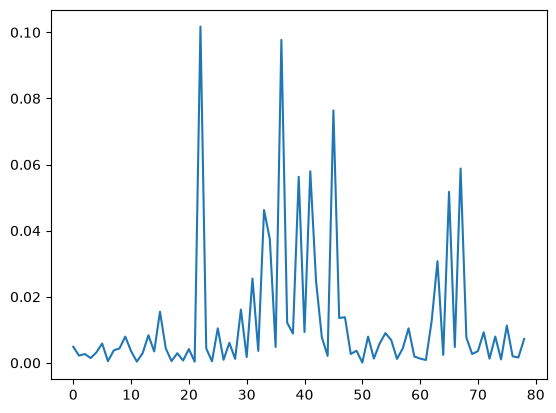

In [24]:
plt.plot(vnm_ats)

In [25]:
outfolder = '/Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/Outputs/'
hs_min.VNMs[0].write_dyn(hs_min.coord, amplitude=20, outfolder=outfolder, name='test_id0.xyz')
hs_min.VNMs[43].write_dyn(hs_min.coord, amplitude=20, outfolder=outfolder, name='test_id43.xyz')

In [26]:
for idx, vnm in enumerate(hs_min.VNMs): 
    vnm_ats = vnm.get_atomic_participation()
    for molec in hs_min.molecules:
        ligs = []
        for lig in molec.ligands:
            indices = lig.get_parent_indices("molecule") 
            ligs.append(float(np.round(np.sum(vnm_ats[indices]),4)))
        mets = []
        for met in molec.metals:
            index = met.get_parent_index("molecule") 
            fcs   = met.get_coord_sphere_idx()
            mets.append(float(np.round(vnm_ats[index],4)))
            mets.append(float(np.round(np.sum(vnm_ats[fcs]),4)))
        print(idx, ligs, mets)

0 [0.333, 0.0924, 0.5697] [0.0049, 0.0249]
1 [0.5161, 0.3119, 0.1637] [0.0082, 0.0255]
2 [0.167, 0.577, 0.2395] [0.0164, 0.0421]
3 [0.3332, 0.1605, 0.4835] [0.0229, 0.031]
4 [0.1475, 0.5248, 0.3179] [0.0099, 0.0297]
5 [0.7807, 0.0962, 0.0862] [0.037, 0.0354]
6 [0.3537, 0.1927, 0.402] [0.0516, 0.0381]
7 [0.3878, 0.3787, 0.2279] [0.0056, 0.0602]
8 [0.3702, 0.2763, 0.2582] [0.0954, 0.0898]
9 [0.1032, 0.5438, 0.3416] [0.0114, 0.0517]
10 [0.4324, 0.2732, 0.2438] [0.0506, 0.0914]
11 [0.2053, 0.123, 0.6608] [0.0108, 0.076]
12 [0.2245, 0.4418, 0.3043] [0.0294, 0.0774]
13 [0.3185, 0.3711, 0.3035] [0.0069, 0.0515]
14 [0.0948, 0.4262, 0.4465] [0.0326, 0.0493]
15 [0.0709, 0.303, 0.608] [0.0181, 0.0406]
16 [0.6486, 0.2655, 0.0735] [0.0123, 0.0282]
17 [0.4619, 0.4284, 0.0606] [0.0491, 0.0609]
18 [0.1355, 0.3454, 0.5127] [0.0063, 0.1862]
19 [0.2924, 0.2787, 0.4242] [0.0048, 0.1575]
20 [0.4672, 0.223, 0.3076] [0.0022, 0.1699]
21 [0.4763, 0.2408, 0.2723] [0.0106, 0.1695]
22 [0.3338, 0.4018, 0.2593] [0.

## Reordered

In [27]:
from scope.vnm_tools import map_vnms

scale = 100
penalty = 1.25

hs_vnms = hs_min.VNMs
ls_vnms = ls_min.VNMs

vnmsA_ordered, vnmsB_ordered, results = map_vnms(hs_vnms, ls_vnms, hs_min.labels, hs_min.coord, ls_min.labels, ls_min.coord, adjmatA=hs_min.molecules[0].adjmat, adjmatB=ls_min.molecules[0].adjmat, f_scale=scale, f_weight=penalty)
print(scale, penalty, assess_vnm_mapping(results["mappings"]))

100 1.25 {'mapping_quality': 0.5141235194237126, 'mean_cost': 0.6652917322339692, 'mean_overlap': 0.3860168699339691, 'mean_squared_overlap': 0.1888422460740917, 'median_overlap': 0.37221962156812355, 'minimum_overlap': 0.0001364279859299734, 'overlap_10th_percentile': 0.13762411937962873, 'fraction_overlap_above_0.8': 0.021645021645021644, 'fraction_overlap_above_0.5': 0.2727272727272727, 'frequency_mae': 13.172458441558435, 'frequency_rmse': 20.26003004300602, 'maximum_frequency_difference': 71.6626}


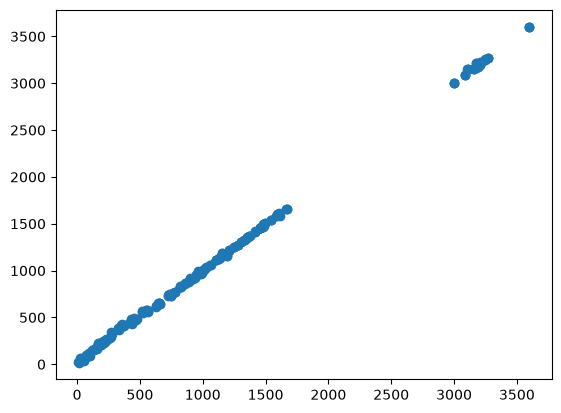

In [28]:
freq_A = [item["freqA"] for item in results["mappings"]]
freq_B = [item["freqB"] for item in results["mappings"]]
plt.scatter(freq_A, freq_B)

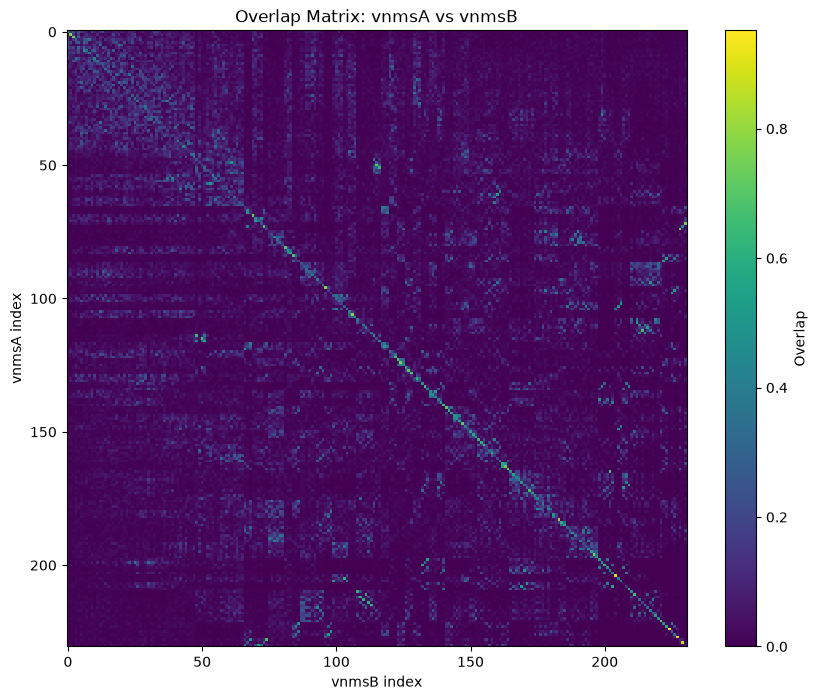

In [29]:
scope.classes_qc.plot_overlap_vnms(vnmsA_ordered, vnmsB_ordered)

## Projection onto the 15-dimensional FeN$_6$ internal subspace

The seven atoms in the first coordination sphere span 21 Cartesian directions. The six rigid FeN$_6$ translation/rotation directions are used only to define their orthogonal complement, leaving a 15-dimensional internal-deformation basis. Each full-molecule normal mode is mass weighted, normalized, restricted to the FeN$_6$ atoms, and projected onto this basis.

The sum of the internal projection weights over a complete set of molecular VNMs should be approximately 15. The weight can nevertheless be distributed over substantially more than 15 VNMs.

In [30]:
def get_fcs_internal_basis(coords, masses):
    coords = np.asarray(coords, dtype=float)
    masses = np.asarray(masses, dtype=float)
    sqrt_masses = np.sqrt(masses)

    center_of_mass = np.average(coords, axis=0, weights=masses)
    centered_coords = coords - center_of_mass

    rigid_vectors = []
    for axis in np.eye(3):
        rigid_vectors.append((sqrt_masses[:, None] * axis).reshape(-1))
    for axis in np.eye(3):
        rotation = np.cross(axis, centered_coords)
        rigid_vectors.append((sqrt_masses[:, None] * rotation).reshape(-1))

    rigid_vectors = np.asarray(rigid_vectors).T
    left_vectors, singular_values, _ = np.linalg.svd(rigid_vectors, full_matrices=True)
    tolerance = max(rigid_vectors.shape) * np.finfo(float).eps * singular_values[0]
    rigid_rank = np.count_nonzero(singular_values > tolerance)
    if rigid_rank != 6:
        raise ValueError(f'Expected six independent rigid directions, found {rigid_rank}')

    return left_vectors[:, rigid_rank:]

def project_vnms_on_fcs(vnms, coords, fcs_indices):
    masses = np.asarray(vnms[0].masses, dtype=float)[fcs_indices]
    internal_basis = get_fcs_internal_basis(np.asarray(coords)[fcs_indices], masses)

    fcs_weights = []
    internal_weights = []
    for vnm in vnms:
        mode = vnm.mass_weight_mode(permanent=False)
        mode = mode / np.linalg.norm(mode)
        fcs_mode = mode[fcs_indices].reshape(-1)

        fcs_weights.append(np.sum(fcs_mode**2))
        coefficients = internal_basis.T @ fcs_mode
        internal_weights.append(np.sum(coefficients**2))

    return np.asarray(fcs_weights), np.asarray(internal_weights), internal_basis

HS: basis=(21, 15), sum=15.028/15, maximum=0.357, effective modes=96.5
LS: basis=(21, 15), sum=14.926/15, maximum=0.424, effective modes=89.3


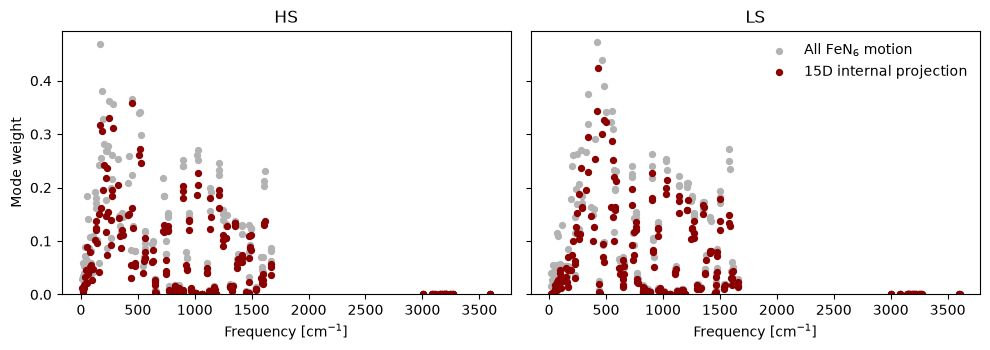

In [31]:
molecule = hs_min.molecules[0]
metal = molecule.metals[0]

metal_index = metal.get_parent_index('molecule')
fcs_indices = [metal_index] + metal.get_coord_sphere_idx()
assert len(fcs_indices) == 7, f'Expected FeN6, found {len(fcs_indices) - 1} coordinating atoms'

hs_fcs_weights, hs_internal_weights, hs_basis = project_vnms_on_fcs(vnmsA_ordered, results['alignment']['coordsA'], fcs_indices)
ls_fcs_weights, ls_internal_weights, ls_basis = project_vnms_on_fcs(vnmsB_ordered, results['alignment']['coordsB'], fcs_indices)

for label, basis, weights in [('HS', hs_basis, hs_internal_weights), ('LS', ls_basis, ls_internal_weights)]:
    effective_modes = np.sum(weights)**2 / np.sum(weights**2)
    print(f'{label}: basis={basis.shape}, sum={np.sum(weights):.3f}/15, maximum={np.max(weights):.3f}, effective modes={effective_modes:.1f}')

fig, axs = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True, tight_layout=True)
for ax, vnms, fcs_weights, internal_weights, label in zip(axs, [vnmsA_ordered, vnmsB_ordered], [hs_fcs_weights, ls_fcs_weights], [hs_internal_weights, ls_internal_weights],['HS', 'LS']):
    frequencies = [vnm.freq_cm for vnm in vnms]
    ax.scatter(frequencies, fcs_weights, s=18, color='0.70', label='All FeN$_6$ motion')
    ax.scatter(frequencies, internal_weights, s=18, color='darkred', label='15D internal projection')
    ax.set_title(label)
    ax.set_xlabel(r'Frequency [cm$^{-1}$]')
    ax.set_ylim(bottom=0)

axs[0].set_ylabel('Mode weight')
axs[1].legend(frameon=False)
plt.show()

## Entropy-weighted FeN$_6$ internal contribution

For each mapped mode, SCOPE computes the harmonic vibrational entropy at the selected temperature. Its internal FeN$_6$ attribution is obtained by multiplying that entropy by the red projection weight:

$$S_{\mathrm{vib,FeN_6}}^X = \sum_i w_{i,\mathrm{FeN_6}}^X S_i^X, \qquad X \in \{\mathrm{HS},\mathrm{LS}\}.$$

The projected entropy difference is then $\Delta S_{\mathrm{vib,FeN_6}}=S_{\mathrm{vib,FeN_6}}^{\mathrm{HS}}-S_{\mathrm{vib,FeN_6}}^{\mathrm{LS}}$. This is an attribution of the entropy of collective molecular modes, not the thermodynamic entropy of an independently separable FeN$_6$ subsystem.

In [ ]:
from scope.thermodynamics import get_Svib

temperature = 298.15

def get_mode_entropies(vnms, temperature):
    entropies = []
    for vnm in vnms:
        entropy = get_Svib([vnm.freq_cm], temperature, freq_units='cm', outunits='kj')
        entropies.append(entropy.value * 1000.0)
    return np.asarray(entropies)

hs_mode_entropies = get_mode_entropies(vnmsA_ordered, temperature)
ls_mode_entropies = get_mode_entropies(vnmsB_ordered, temperature)

delta_mode_entropies = hs_mode_entropies - ls_mode_entropies
hs_internal_entropies = hs_internal_weights * hs_mode_entropies
ls_internal_entropies = ls_internal_weights * ls_mode_entropies
delta_internal_entropies = hs_internal_entropies - ls_internal_entropies

delta_Svib = np.sum(delta_mode_entropies)
delta_Svib_internal = np.sum(delta_internal_entropies)

print(f'T = {temperature:.2f} K')
print(f'Total dSvib:          {delta_Svib:.2f} J mol-1 K-1')
print(f'Internal FeN6 dSvib: {delta_Svib_internal:.2f} J mol-1 K-1')
print(f'Attributed fraction: {100 * delta_Svib_internal / delta_Svib:.1f}%')

In [ ]:
pair_frequencies = 0.5 * np.asarray([
    vnm_hs.freq_cm + vnm_ls.freq_cm
    for vnm_hs, vnm_ls in zip(vnmsA_ordered, vnmsB_ordered)
])
frequency_order = np.argsort(pair_frequencies)

def plot_entropy_contributions(max_frequency=None):
    fig, axs = plt.subplots(1, 2, figsize=(10, 3.6), tight_layout=True)

    axs[0].scatter(pair_frequencies, delta_mode_entropies, s=18, color='0.70', label=r'Total $\Delta S_i$')
    axs[0].scatter(pair_frequencies, delta_internal_entropies, s=18, color='darkred', label=r'Internal FeN$_6$ attribution')
    axs[0].axhline(0, color='black', linewidth=0.8)
    axs[0].set_xlabel(r'Mean mapped frequency [cm$^{-1}$]')
    axs[0].set_ylabel(r'Mode-pair contribution [J mol$^{-1}$ K$^{-1}$]')
    axs[0].legend(frameon=False)

    axs[1].plot(pair_frequencies[frequency_order], np.cumsum(delta_mode_entropies[frequency_order]), color='0.45', label=r'Total $\Delta S_{\mathrm{vib}}$')
    axs[1].plot(pair_frequencies[frequency_order], np.cumsum(delta_internal_entropies[frequency_order]), color='darkred', label=r'Internal FeN$_6$ attribution')
    axs[1].axhline(0, color='black', linewidth=0.8)
    axs[1].set_xlabel(r'Mean mapped frequency [cm$^{-1}$]')
    axs[1].set_ylabel(r'Cumulative contribution [J mol$^{-1}$ K$^{-1}$]')
    axs[1].legend(frameon=False)

    if max_frequency is None:
        fig.suptitle('Complete frequency range')
    else:
        for ax in axs:
            ax.set_xlim(0, max_frequency)
        fig.suptitle(rf'Low-frequency region: 0--{max_frequency} cm$^{{-1}}$')

    plt.show()


plot_entropy_contributions()
plot_entropy_contributions(max_frequency=600)

## Paired versus unpaired frequency resolution

The paired analysis assigns each HS--LS difference to the mean frequency of the modes matched by `map_vnms()`. The unpaired analysis retains the original frequency of every mode: HS contributions are added and LS contributions are subtracted independently. Both approaches must give the same final entropy difference, but they can distribute it differently across frequency.

In [ ]:
hs_frequencies = np.asarray([vnm.freq_cm for vnm in vnmsA_ordered])
ls_frequencies = np.asarray([vnm.freq_cm for vnm in vnmsB_ordered])
frequency_grid = np.unique(np.concatenate([hs_frequencies, ls_frequencies, pair_frequencies]))

def cumulative_contribution(frequency_grid, frequencies, contributions):
    values = []
    for frequency in frequency_grid:
        values.append(np.sum(contributions[frequencies <= frequency]))
    return np.asarray(values)

paired_total_cumulative = cumulative_contribution(
    frequency_grid, pair_frequencies, delta_mode_entropies
)
unpaired_total_cumulative = (
    cumulative_contribution(frequency_grid, hs_frequencies, hs_mode_entropies)
    - cumulative_contribution(frequency_grid, ls_frequencies, ls_mode_entropies)
)

paired_internal_cumulative = cumulative_contribution(
    frequency_grid, pair_frequencies, delta_internal_entropies
)
unpaired_internal_cumulative = (
    cumulative_contribution(frequency_grid, hs_frequencies, hs_internal_entropies)
    - cumulative_contribution(frequency_grid, ls_frequencies, ls_internal_entropies)
)

print(f'Total endpoint, paired/unpaired:    {paired_total_cumulative[-1]:.3f} / {unpaired_total_cumulative[-1]:.3f}')
print(f'FeN6 endpoint, paired/unpaired:     {paired_internal_cumulative[-1]:.3f} / {unpaired_internal_cumulative[-1]:.3f}')
print(f'Maximum total cumulative difference: {np.max(np.abs(paired_total_cumulative - unpaired_total_cumulative)):.2f}')
print(f'Maximum FeN6 cumulative difference:  {np.max(np.abs(paired_internal_cumulative - unpaired_internal_cumulative)):.2f}')

In [ ]:
def plot_paired_unpaired_cumulative(max_frequency=None):
    fig, axs = plt.subplots(1, 2, figsize=(10, 3.6), tight_layout=True)

    axs[0].step(frequency_grid, paired_total_cumulative, where='post', color='black', label='Paired')
    axs[0].step(frequency_grid, unpaired_total_cumulative, where='post', color='darkorange', linestyle='--', label='Unpaired')
    axs[0].set_title(r'Total $\Delta S_{\mathrm{vib}}$')

    axs[1].step(frequency_grid, paired_internal_cumulative, where='post', color='darkred', label='Paired')
    axs[1].step(frequency_grid, unpaired_internal_cumulative, where='post', color='royalblue', linestyle='--', label='Unpaired')
    axs[1].set_title(r'Internal FeN$_6$ attribution')

    for ax in axs:
        ax.axhline(0, color='0.5', linewidth=0.8)
        ax.set_xlabel(r'Frequency [cm$^{-1}$]')
        ax.set_ylabel(r'Cumulative contribution [J mol$^{-1}$ K$^{-1}$]')
        ax.legend(frameon=False)
        if max_frequency is not None:
            ax.set_xlim(0, max_frequency)

    if max_frequency is None:
        fig.suptitle('Complete frequency range')
    else:
        fig.suptitle(rf'Low-frequency region: 0--{max_frequency} cm$^{{-1}}$')
    plt.show()


plot_paired_unpaired_cumulative()
plot_paired_unpaired_cumulative(max_frequency=600)

In [ ]:
frequency_bins = np.asarray([1, 50, 100, 200, 400, 600, 800, 1600, 4000], dtype=float)
bin_labels = [f'{int(low)}--{int(high)}' for low, high in zip(frequency_bins[:-1], frequency_bins[1:])]

def bin_contributions(frequencies, contributions, bins):
    return np.histogram(frequencies, bins=bins, weights=contributions)[0]

paired_total_bins = bin_contributions(pair_frequencies, delta_mode_entropies, frequency_bins)
unpaired_total_bins = (
    bin_contributions(hs_frequencies, hs_mode_entropies, frequency_bins)
    - bin_contributions(ls_frequencies, ls_mode_entropies, frequency_bins)
)
paired_internal_bins = bin_contributions(pair_frequencies, delta_internal_entropies, frequency_bins)
unpaired_internal_bins = (
    bin_contributions(hs_frequencies, hs_internal_entropies, frequency_bins)
    - bin_contributions(ls_frequencies, ls_internal_entropies, frequency_bins)
)

x = np.arange(len(bin_labels))
width = 0.38
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), tight_layout=True)

for ax, paired, unpaired, title in zip(
    axs,
    [paired_total_bins, paired_internal_bins],
    [unpaired_total_bins, unpaired_internal_bins],
    [r'Total $\Delta S_{\mathrm{vib}}$', r'Internal FeN$_6$ attribution'],
):
    ax.bar(x - width / 2, paired, width, color='0.35', label='Paired')
    ax.bar(x + width / 2, unpaired, width, color='darkorange', label='Unpaired')
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_xticks(x, bin_labels, rotation=45, ha='right')
    ax.set_xlabel(r'Frequency window [cm$^{-1}$]')
    ax.set_ylabel(r'Contribution [J mol$^{-1}$ K$^{-1}$]')
    ax.set_title(title)
    ax.legend(frameon=False)

plt.show()